In [43]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from skimage.transform import warp_polar

In [155]:
crop_dir = "/datafiles/crops/2951"
img_name = "24429_crop_g2.png"
img_name = "24380_crop_g23.png"
img_name = "24416_crop_g166.png"

In [156]:
import os
os.getcwd()

'/home/xgupke/Documents/projects/EmmaElinTrombocytes'

In [157]:
img = Image.open(f"{os.getcwd()}{crop_dir}/{img_name}")
img = np.array(img)

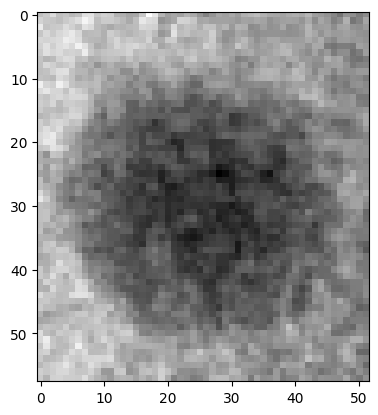

In [158]:
plt.imshow(img, cmap="gray")

In [159]:
def znorm(img):
    return (img - np.mean(img)) / np.std(img)

In [160]:
# normalize
# img = (img - img.min()) / (img.max() - img.min())
img = znorm(img)

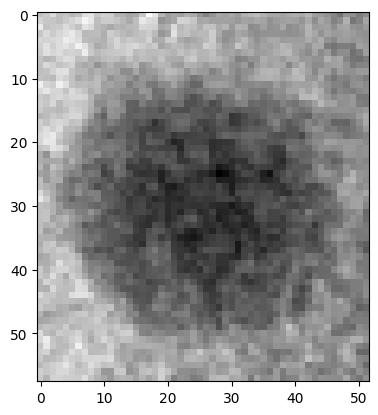

In [161]:
plt.imshow(img, cmap="gray")

In [162]:
polar_img = warp_polar(
    img,
    center=(img.shape[0] / 2, img.shape[1] / 2),
    radius=img.shape[0] / 2,
    scaling="linear"
)

In [163]:
polar_img.shape

(360, 29)

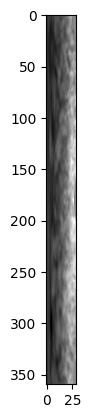

In [164]:
plt.imshow(polar_img, cmap="gray")

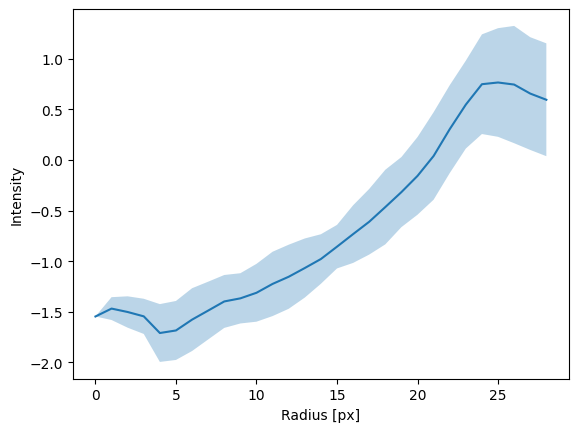

In [165]:
mean_profile = np.mean(polar_img, axis=0)
std_profile = np.std(polar_img, axis=0)

r = np.arange(polar_img.shape[1])

plt.plot(r, mean_profile)
plt.fill_between(
    r,
    mean_profile - std_profile,
    mean_profile + std_profile,
    alpha=0.3
)

plt.xlabel("Radius [px]")
plt.ylabel("Intensity")
plt.show()

In [166]:
img.shape

(58, 52)

In [167]:
def crop_center_square_by_radius(image, radius_px):
    radius_px = int(radius_px)

    h, w = image.shape[:2]
    cy, cx = h // 2, w // 2

    y1 = cy - radius_px
    y2 = cy + radius_px
    x1 = cx - radius_px
    x2 = cx + radius_px

    crop = image[y1:y2, x1:x2]

    plt.imshow(crop, cmap="gray")
    plt.axis("off")
    plt.show()

    return crop

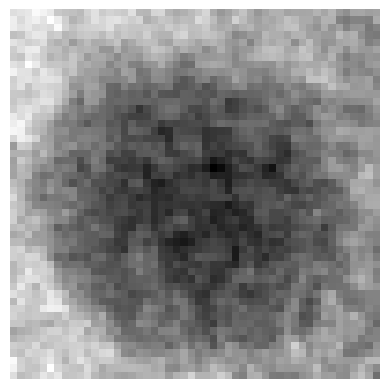

In [168]:
c = crop_center_square_by_radius(img, 25)

In [169]:
from skimage.filters import threshold_otsu, median, gaussian
from skimage.morphology import remove_small_objects, disk, remove_small_holes, closing

In [170]:
def get_mask(img_arr):
    # normalize
    img = znorm(img_arr)
    # img = median(img, disk(3))
    img = gaussian(img, sigma=1, preserve_range=True)
    
    # thresholding
    img_otsu = img < threshold_otsu(img)
    
    # morphological operations
    img_mask = remove_small_holes(img_otsu)
    img_mask = remove_small_objects(img_mask, max_size=50)
    img_mask = closing(img_mask, disk(3))

    return img_mask

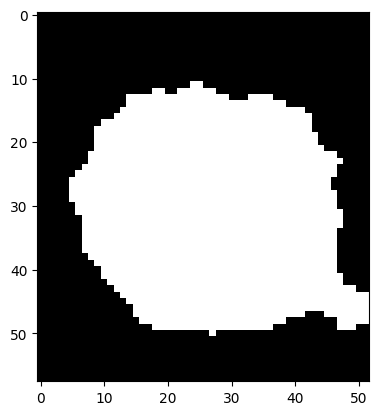

In [171]:
img_mask = get_mask(img)
plt.imshow(img_mask, cmap="gray")

In [172]:
polar_mask = warp_polar(
    img_mask,
    center=(img_mask.shape[0] / 2, img_mask.shape[1] / 2),
    radius=img_mask.shape[0] / 2,
    scaling="linear")
valid_angles = ~polar_mask[:, -5]
selected_polar_mask = polar_mask[valid_angles, :]
selected_polar_mask.shape

(341, 29)

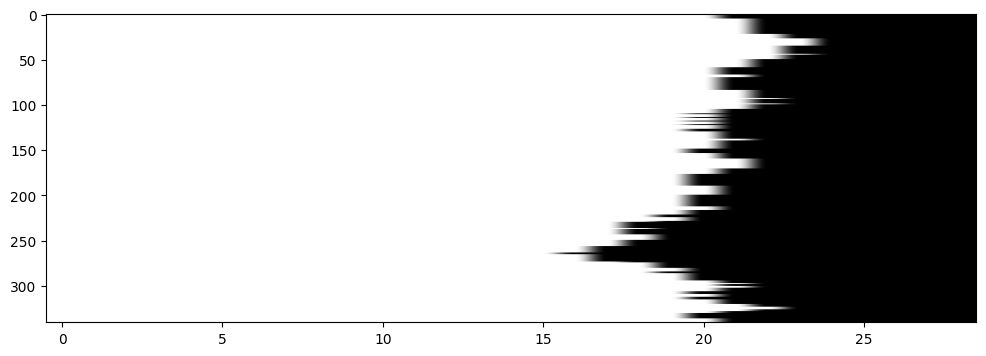

In [173]:
plt.figure(figsize=(12, 4))
plt.imshow(selected_polar_mask, cmap="gray", aspect="auto")

In [174]:
np.mean(selected_polar_mask, axis=0)

array([1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 0.9941349 , 0.95014663, 0.88856305, 0.83284457,
       0.62463343, 0.29912023, 0.09677419, 0.02639296, 0.        ,
       0.        , 0.        , 0.        , 0.        ])

In [175]:
def find_zeros(polar_mask):
    zeros_row = []
    for r in polar_mask:
        zeros = np.where(r == 0)[0][0]
        zeros_row.append(zeros)

    return zeros_row

In [176]:
z = find_zeros(selected_polar_mask)

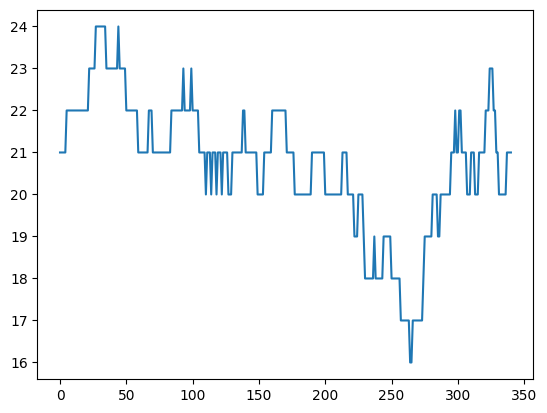

In [177]:
plt.plot(find_zeros(selected_polar_mask))

In [178]:
np.median(z)

np.float64(21.0)

In [179]:
def diameter_from_mask_touching_border(img_mask, px_size=3.22):

    def find_zeros(polar_mask):
        zeros_row = []
        for r in polar_mask:
            zeros = np.where(r == 0)[0][0]
            zeros_row.append(zeros)

        return zeros_row

    polar_mask = warp_polar(
        img_mask,
        center=(img_mask.shape[0] / 2, img_mask.shape[1] / 2),
        radius=img_mask.shape[0] / 2,
        scaling="linear"
    )
    valid_angles = ~polar_mask[:, -5]
    selected_polar_mask = polar_mask[valid_angles, :]
    
    selected_zeros = find_zeros(selected_polar_mask)

    return np.median(selected_zeros) * px_size * 2

In [180]:
diameter_from_mask_touching_border(img_mask)

np.float64(135.24)

In [116]:
def mask_touches_border(mask):
    return (
        mask[0, :].any() or
        mask[-1, :].any() or
        mask[:, 0].any() or
        mask[:, -1].any()
    )

In [117]:
from skimage.measure import label, regionprops

In [185]:
def evaluate_granule(img_arr, pixel_size_nm=3.22, diameter_range=(50, 300), aspect_ratio_max=1.25):
    
    # normalize
    img = znorm(img_arr)
    # img = median(img, disk(3))
    img = gaussian(img, sigma=1, preserve_range=True)
    
    # thresholding
    img_otsu = img < threshold_otsu(img)
    
    # morphological operations
    img_mask = remove_small_holes(img_otsu)
    img_mask = remove_small_objects(img_mask, max_size=50)
    img_mask = closing(img_mask, disk(3))
    
    mask_touching_border = mask_touches_border(img_mask)
    print(f"mask_touches_border: {mask_touching_border}")

    rejection_reason = "N.A."
    quality_check = True
    if not mask_touching_border:
        # labeling and region properties
        lab = label(img_mask)
        props = regionprops(lab)
        
        if len(props) == 0:
            return None  # No objects found
        
        obj = props[0]
        
        major = obj.axis_major_length
        minor = obj.axis_minor_length
        diameter_mean_axes = (major + minor) / 2
        
        # check the quality of the granule based on diameter and aspect ratio
        # Check diameter range and aspect ratio
        quality_check = True
        if not (diameter_range[0] <= diameter_mean_axes * pixel_size_nm <= diameter_range[1]):
            quality_check = False  # Diameter out of range
            rejection_reason = "Diameter out of range"
            return img_mask, diameter_mean_axes * pixel_size_nm, quality_check, rejection_reason

        # check aspect ratio only if diameter is within range
        aspect_ratio = major / minor if minor != 0 else float('inf')
        if aspect_ratio > aspect_ratio_max:
            quality_check = False  # Aspect ratio too high
            rejection_reason = "Shape too thin"
        
        return img_mask, diameter_mean_axes * pixel_size_nm, quality_check, rejection_reason
    
    else:
        diameter_median = diameter_from_mask_touching_border(img_mask, pixel_size_nm)
        if not (diameter_range[0] <= diameter_median <= diameter_range[1]):
            quality_check = False
            rejection_reason = "Diameter out of range"
        else:
            quality_check = True
        
        return img_mask, diameter_median, quality_check, rejection_reason


24380_crop_g23.png
mask_touches_border: True
validity check: True

24416_crop_g166.png
mask_touches_border: True
validity check: True

24434_crop_g54.png
mask_touches_border: False
validity check: True

24393_crop_g60.png
mask_touches_border: False
validity check: True

24381_crop_g19.png
mask_touches_border: True
validity check: True

24438_crop_g73.png
mask_touches_border: False
validity check: True

24385_crop_g29.png
mask_touches_border: False
validity check: True


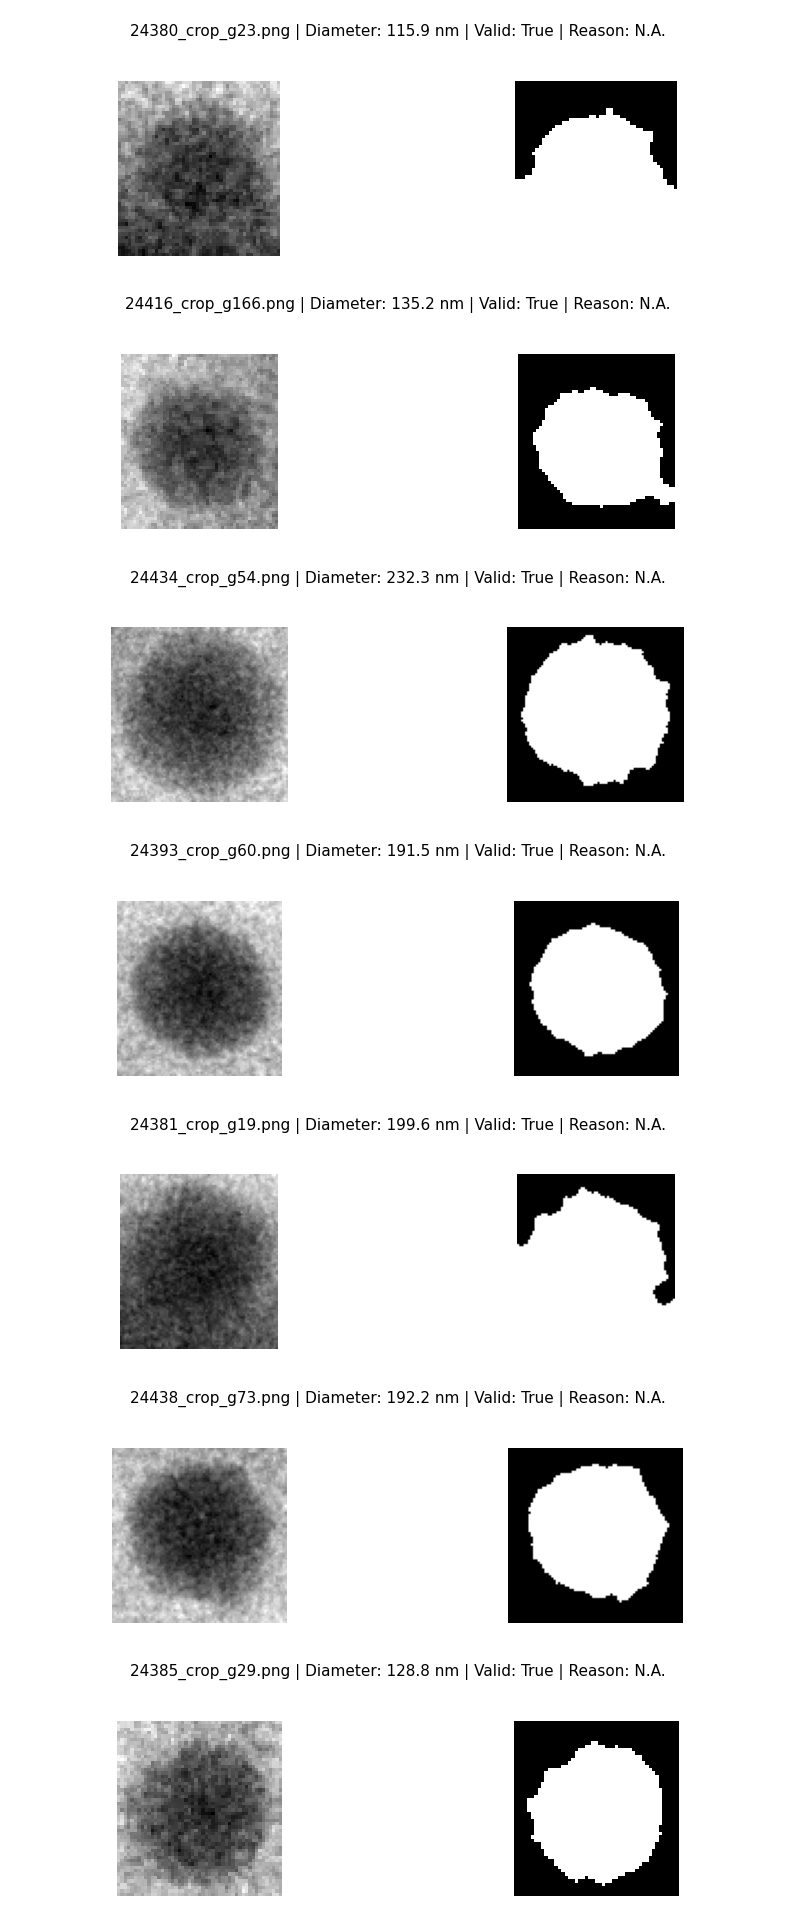

In [186]:
from pathlib import Path
import os
import random
from matplotlib.gridspec import GridSpec

crop_dir = "/datafiles/crops/2951"

img_paths = [
    p for p in Path(os.getcwd(), crop_dir.lstrip("/")).iterdir()
    if p.is_file() and p.suffix.lower() == ".png"
]

random_imgs = random.sample(img_paths, min(5, len(img_paths)))
random_imgs.insert(0, Path(os.getcwd(), crop_dir.lstrip("/"), "24416_crop_g166.png"))
random_imgs.insert(0, Path(os.getcwd(), crop_dir.lstrip("/"), "24380_crop_g23.png"))

pixel_size_nm = 3.22
n = len(random_imgs)

fig = plt.figure(figsize=(10, 3.5 * n))

gs = GridSpec(
    nrows=2 * n,
    ncols=2,
    height_ratios=[0.25, 1] * n,
    hspace=0.25,
    wspace=0.05
)

for row, img_path in enumerate(random_imgs):
    print("\n" + img_path.name)
    img_arr = np.array(Image.open(img_path))

    result = evaluate_granule(
        img_arr,
        pixel_size_nm=pixel_size_nm,
        diameter_range=(50, 300),
        aspect_ratio_max=1.25
    )

    if result is None:
        img_mask = np.zeros_like(img_arr)
        row_title = f" {img_path.name} | Diameter: N.A. | Valid: False | Reason: No objects found"
    else:
        img_mask, diameter_nm, quality_check, rejection_reason = result

        row_title = (
            f"{img_path.name} | "
            f"Diameter: {diameter_nm:.1f} nm | "
            f"Valid: {quality_check} | "
            f"Reason: {rejection_reason}"
        )
        print(f"validity check: {quality_check}")

    ax_title = fig.add_subplot(gs[2 * row, :])
    ax_raw = fig.add_subplot(gs[2 * row + 1, 0])
    ax_mask = fig.add_subplot(gs[2 * row + 1, 1])

    ax_title.axis("off")
    ax_title.text(
        0.5,
        0.5,
        row_title,
        ha="center",
        va="center",
        fontsize=11
    )

    ax_raw.imshow(img_arr, cmap="gray")
    ax_raw.axis("off")

    ax_mask.imshow(img_mask, cmap="gray")
    ax_mask.axis("off")

plt.show()